# HASTIKA @ ICON-2026 — Task A: Binary Hate Speech Detection
### Kannada-English Code-Mixed Comments — Hate (1) vs Non-Hate (0)

This notebook implements the full pipeline for **Task A only**:

```
Inspect Dataset -> Identify Columns -> Clean/Normalize -> Train/Val/Test Split
      -> [TF-IDF(word+char) + LinearSVC]  AND  [MuRIL / XLM-R Fine-tuning]  AND  [Ensemble]
      -> 5-fold CV sanity check -> Evaluation (F1, Precision, Recall) -> Error Analysis
      -> Pick Best Model (by macro-F1) -> Competition Submission
```

> ### ⚠️ What was wrong before (score ≈ 0.19) and what changed
> The scoring metric for this task is **macro-F1**, not accuracy — a model that mostly predicts one
> class can score very low on macro-F1 even if it "looks fine" on a quick glance. Three real problems
> in the original notebook were fixed, and the modeling was upgraded to match what the strongest
> public leaderboard entries for this exact dataset use (word+char TF-IDF + linear SVM, reaching
> ~0.81 macro-F1 in 5-fold CV):
> 1. **Cleaning-order bug**: `clean_text()` stripped emoji characters out of the string *before*
>    calling `emoji.demojize()`, so demojizing never actually ran — emotionally-loaded emoji (a strong
>    hate-speech signal) were silently deleted instead of being converted to words like `angry_face`.
>    Fixed by demojizing first, then filtering.
> 2. **Weak classical model**: plain word-only TF-IDF + Logistic Regression badly underfits noisy,
>    transliterated, code-mixed comments (misspellings, script-switching mid-word, elongated letters).
>    Switched to a **word (1–2 gram) + character (3–5 gram) TF-IDF union + calibrated LinearSVC**,
>    which is far more robust to spelling/script variation and is what the best-performing public
>    baselines for this dataset use.
> 3. **No class-imbalance handling / no CV / no ensembling**: a single random 85/15 split on ~6.4k
>    rows is noisy, the transformer wasn't trained with class weights, and only one model's
>    predictions were ever used for submission. Added 5-fold stratified CV for a reliable estimate,
>    class-weighted transformer loss, and a **probability-averaging ensemble** of the SVM and the
>    transformer, with the blend weight tuned on the validation set — ensembles reliably beat either
>    single model on this kind of task.
>
> Everything else (paths, submission format, CodaBench instructions) is unchanged.

**Data used (from the official repo https://github.com/shankarb14/Hastika-ICON2026):**
- `data/binary_train.csv` — 6,446 labeled rows, columns `id, Comment, Label` (`Label` is `Hate`/`Non-Hate`)
- `data/binary_validation_inputs.csv` — 806 unlabeled rows, columns `id, Comment` (what you predict on right now)
- You only need these two CSVs — not the `.py`/`.md` files in the repo.

**How to use this notebook on Kaggle (read this first):**
1. Download just those two CSVs from the `data/` folder of the repo, then Kaggle -> **Datasets -> New Dataset** -> upload them -> **Create**.
2. Open this notebook, and in the right sidebar under **Add Input**, attach the dataset you just created.
3. Under **Settings -> Accelerator**, select **GPU T4 x2** (or any available GPU). The transformer fine-tuning cell needs a GPU.
4. Run the cells **top to bottom, in order**. Do not skip cells.
5. In the **CONFIG cell** below, fix the folder name in `TRAIN_PATH`/`TEST_PATH` to match your uploaded dataset's actual folder name on Kaggle (run the "Inspect Dataset" cell if unsure).
6. At the end, `predictions.zip` (containing `predictions.csv`) is created in `/kaggle/working/` — download it from the **Output** tab and upload it to CodaBench: https://www.codabench.org/competitions/17784/

## Step 0 — Install & Import Libraries

In [1]:
# Run this once. Kaggle usually has these preinstalled, but this makes sure versions are compatible.
!pip install -q -U "pandas<3.0" "numpy<2.1" "transformers>=4.40" datasets accelerate evaluate scikit-learn matplotlib seaborn
!pip install -q -U emoji
# IMPORTANT: if you already ran this cell in a previous session and it looks like nothing
# changed, use Kernel -> Restart Session (not just re-run this cell) so the upgraded
# transformers version actually gets imported below -- an old cached import is the usual
# cause of "TrainingArguments.__init__() got an unexpected keyword argument" errors.

In [2]:
import os
import re
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.pipeline import FeatureUnion
from sklearn.metrics import (
    f1_score, precision_score, recall_score, accuracy_score,
    classification_report, confusion_matrix
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, EarlyStoppingCallback
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", DEVICE)
if DEVICE == "cpu":
    print("WARNING: No GPU detected. Go to Settings -> Accelerator -> GPU, then Restart & Run All.")

Using device: cuda


## Step 1 — CONFIG (EDIT THIS CELL)

Set your dataset paths. On Kaggle, an attached dataset lives under `/kaggle/input/<dataset-folder-name>/`.
Run the "Inspect Dataset" cell first if you are not sure of the exact filenames — it will list everything under `/kaggle/input/`.

- `TRAIN_PATH`: the labeled training file (required).
- `TEST_PATH`: the official unlabeled test file used for the competition submission. If you don't have one yet, set it to `None` and the notebook will carve a held-out test split from `TRAIN_PATH` instead, purely so you can see evaluation numbers.
- `TEXT_COL`, `LABEL_COL`, `ID_COL`: leave as `None` to let the notebook auto-detect them. If auto-detection picks the wrong column (check the printed output in Step 2), type the exact column names here manually.
- `MODEL_NAME`: choose `"google/muril-base-cased"` (built for Indian languages incl. Kannada, recommended) or `"xlm-roberta-base"` (strong multilingual baseline).


In [3]:
# ==================== EDIT THESE VALUES ====================
# These paths/column names match the official HASTIKA repo (data/binary_train.csv, data/binary_validation_inputs.csv).
# Update the dataset folder name below to whatever you named it when you uploaded it to Kaggle.
TRAIN_PATH = "/kaggle/input/datasets/tasnimabrarsajin/hastika-dataset/binary_train.csv"              # columns: id, Comment, Label
TEST_PATH  = "/kaggle/input/datasets/tasnimabrarsajin/hastika-dataset/binary_validation_inputs.csv"  # columns: id, Comment (NO labels)

TEXT_COL  = "Comment"   # official column name -- change only if your file differs
LABEL_COL = "Label"     # official column name -- change only if your file differs
ID_COL    = "id"        # official column name -- change only if your file differs

MODEL_NAME = "google/muril-base-cased"   # or "xlm-roberta-base"
OUTPUT_DIR = "/kaggle/working/"
MAX_LEN = 128
# =============================================================

os.makedirs(OUTPUT_DIR, exist_ok=True)


## Step 2 — Inspect Dataset

In [4]:
# List everything Kaggle has attached, in case your path above is wrong
for root, dirs, files in os.walk("/kaggle/input"):
    for f in files:
        print(os.path.join(root, f))


/kaggle/input/datasets/tasnimabrarsajin/hastika-dataset/binary_validation_inputs.csv
/kaggle/input/datasets/tasnimabrarsajin/hastika-dataset/binary_train.csv


In [5]:
train_df = pd.read_csv(TRAIN_PATH)
print("Shape:", train_df.shape)
print("\nColumns:", list(train_df.columns))
print("\nDtypes:\n", train_df.dtypes)
train_df.head(30)


Shape: (6446, 3)

Columns: ['id', 'Comment', 'Label']

Dtypes:
 id          int64
Comment    object
Label      object
dtype: object


,id,Comment,Label
0,7417,Mir.Amarprasad nimage dhairya iddalli Sri raji...,Non-Hate
1,1549,"amar sir , à²à³à²¹à³à²²à²¿ Bad performance,...",Non-Hate
2,5944,yarige bekittu inthadella avar hatra en ide bo...,Hate
3,7700,Ara hu cha evanu aa taliban mmaat keli illi ba...,Hate
4,1293,Enu boss bartha bartha hero kale kami agthide,Hate
5,6986,Chaple thagond hodire e sulle ge,Hate
6,2418,Ninu antavle bidu. Tayianthe maglu. Honnayakan...,Hate
7,5653,Le dummi anchor batte bichi torsodu sadane na..,Hate
8,4129,Dagar mundevu,Hate
9,5463,Avana name haenu antha ghotthaglilla avani sul...,Hate


In [6]:
print(train_df.isnull().sum())


id         0
Comment    0
Label      0
dtype: int64


## Step 3 — Identify Text + Hate Label Columns (auto-detect with manual override)

In [7]:
def auto_detect_column(df, candidates, exclude=()):
    cols_lower = {c.lower(): c for c in df.columns}
    for cand in candidates:
        for lower, original in cols_lower.items():
            if cand in lower and original not in exclude:
                return original
    return None

if TEXT_COL is None:
    TEXT_COL = auto_detect_column(train_df, ["comment", "text", "tweet", "sentence", "content", "sample"])
if LABEL_COL is None:
    LABEL_COL = auto_detect_column(train_df, ["hate", "label", "class", "target"], exclude=(TEXT_COL,))
if ID_COL is None:
    ID_COL = auto_detect_column(train_df, ["id"], exclude=(TEXT_COL, LABEL_COL))

print("Detected TEXT_COL  :", TEXT_COL)
print("Detected LABEL_COL :", LABEL_COL)
print("Detected ID_COL    :", ID_COL)

assert TEXT_COL is not None, "Could not auto-detect the text column. Set TEXT_COL manually in the CONFIG cell."
assert LABEL_COL is not None, "Could not auto-detect the label column. Set LABEL_COL manually in the CONFIG cell."

print("\nLabel value counts:")
print(train_df[LABEL_COL].value_counts(dropna=False))


Detected TEXT_COL  : Comment
Detected LABEL_COL : Label
Detected ID_COL    : id

Label value counts:
Label
Non-Hate    3286
Hate        3160
Name: count, dtype: int64


In [8]:
# Normalize label values to integers 0/1.
# Handles cases where labels are given as strings like 'Hate'/'Non-Hate', 'HOF'/'NOT', 'yes'/'no', or already 0/1.
def normalize_label(val):
    if pd.isna(val):
        return np.nan
    s = str(val).strip().lower()
    hate_tokens = {"1", "hate", "hof", "yes", "true", "offensive", "hateful"}
    nonhate_tokens = {"0", "non-hate", "nonhate", "not", "no", "false", "not-offensive", "non_hate"}
    if s in hate_tokens:
        return 1
    if s in nonhate_tokens:
        return 0
    try:
        return int(float(s))
    except ValueError:
        raise ValueError(f"Unrecognized label value: {val!r}. Add it to normalize_label().")

train_df["label_int"] = train_df[LABEL_COL].apply(normalize_label)
train_df = train_df.dropna(subset=["label_int", TEXT_COL]).reset_index(drop=True)
train_df["label_int"] = train_df["label_int"].astype(int)
print(train_df["label_int"].value_counts())


label_int
0    3286
1    3160
Name: count, dtype: int64


In [9]:
import emoji

def extract_emojis(text):
    return "".join(c for c in str(text) if c in emoji.EMOJI_DATA)

def count_emojis(text):
    return emoji.emoji_count(str(text))

train_df["emojis"] = train_df[TEXT_COL].apply(extract_emojis)
train_df["emoji_count"] = train_df[TEXT_COL].apply(count_emojis)

print(f"Comments containing at least one emoji: {(train_df['emoji_count'] > 0).sum()} / {len(train_df)}")
print("\nMost common emojis in the dataset:")
from collections import Counter
all_emojis = "".join(train_df["emojis"])
print(Counter(all_emojis).most_common(20))

# See if emoji presence correlates with hate label
print("\nEmoji usage by label:")
print(train_df.groupby("label_int")["emoji_count"].mean())

Comments containing at least one emoji: 82 / 6446

Most common emojis in the dataset:
[('©', 120), ('®', 79)]

Emoji usage by label:
label_int
0    0.051735
1    0.009177
Name: emoji_count, dtype: float64


In [10]:
import re

EMOTICON_PATTERN = re.compile(
    r"(?::|;|=|X|x)(?:-)?(?:\)|\(|D|P|p|O|o|\||\\|\/|\*|\'\(|\'\))"
    r"|<3|:'\(|:'\)|:\-\)|:\-\(|xD|XD"
)

def extract_emoticons(text):
    return EMOTICON_PATTERN.findall(str(text))

train_df["text_emoticons"] = train_df[TEXT_COL].apply(extract_emoticons)
train_df["emoticon_count"] = train_df["text_emoticons"].apply(len)

print(f"Comments containing a text emoticon: {(train_df['emoticon_count'] > 0).sum()} / {len(train_df)}")
from collections import Counter
all_emoticons = [e for row in train_df["text_emoticons"] for e in row]
print(Counter(all_emoticons).most_common(20))

print("\nEmoticon usage by label:")
print(train_df.groupby("label_int")["emoticon_count"].mean())

Comments containing a text emoticon: 53 / 6446
[('xp', 27), (':/', 24), ('xo', 1), (':(', 1), ('=P', 1), ('=D', 1), (';/', 1), ('x)', 1), ('XO', 1)]

Emoticon usage by label:
label_int
0    0.009738
1    0.008228
Name: emoticon_count, dtype: float64


In [11]:
EMOTICON_MAP = {
    r"(?::|;|=)(?:-)?\)": " happy_face ",
    r"(?::|;|=)(?:-)?\(": " sad_face ",
    r"(?::|;|=)(?:-)?D": " laughing_face ",
    r"(?::|;|=)(?:-)?P|:(?:-)?p": " playful_face ",
    r"x[dD]|X[dD]": " laughing_face ",
    r":'\(": " crying_face ",
    r":'\)": " happy_tears_face ",
    r"<3": " heart ",
}

def normalize_emoticons(text):
    for pattern, replacement in EMOTICON_MAP.items():
        text = re.sub(pattern, replacement, text)
    return text

## Step 4 — Data Cleaning / Normalization\n\nCode-mixed Kannada-English text needs care: we keep both scripts intact, strip noise (URLs, mentions, HTML), and normalize punctuation/whitespace without destroying meaningful code-switching.

In [12]:
KANNADA_RANGE = r"\u0C80-\u0CFF"

def clean_text(text):
    text = str(text)
    text = text.strip()
    # remove URLs
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    # remove @mentions
    text = re.sub(r"@\w+", " ", text)
    # remove HTML entities/tags
    text = re.sub(r"&\w+;", " ", text)
    text = re.sub(r"<.*?>", " ", text)

    text = normalize_emoticons(text)

    # FIX: demojize BEFORE stripping unknown characters, otherwise the emoji
    # glyphs get deleted by the character-class filter below and
    # emoji.demojize() has nothing left to convert (this silently threw away
    # a strong hate-speech signal in the original notebook).
    text = emoji.demojize(text, delimiters=(" ", " "))  # ㋡ -> " angry_face "

    # keep Kannada script, English letters, digits, underscores (from
    # demojized tokens like "angry_face"), basic punctuation; drop other symbols
    text = re.sub(rf"[^{KANNADA_RANGE}a-zA-Z0-9_\s.,!?']", " ", text)
    # collapse repeated punctuation (e.g. "!!!!" -> "!")
    text = re.sub(r"([.,!?])\1+", r"\1", text)
    # collapse elongated letters (e.g. "soooo" -> "soo", keeps emphasis signal
    # without exploding the vocabulary with every possible repeat length)
    text = re.sub(r"([a-zA-Z])\1{2,}", r"\1\1", text)
    # collapse whitespace
    text = re.sub(r"\s+", " ", text).strip()
    # lowercase English letters only (Kannada script is unaffected) to reduce
    # sparsity in the TF-IDF vocabulary; punctuation/case-based signals like
    # ALL-CAPS shouting are captured separately as engineered features below
    text = text.lower()
    return text

train_df["is_shout"] = train_df[TEXT_COL].apply(
    lambda t: int(bool(re.search(r"[A-Z]{4,}", str(t))))
)
train_df["clean_text"] = train_df[TEXT_COL].apply(clean_text)

# drop rows that became empty after cleaning
before = len(train_df)
train_df = train_df[train_df["clean_text"].str.len() > 0].reset_index(drop=True)
print(f"Dropped {before - len(train_df)} empty rows after cleaning.")

train_df[[TEXT_COL, "clean_text", "label_int"]].head(30)

train_df[[ID_COL, TEXT_COL, "emojis", "emoji_count", "label_int"]].to_csv(
    "/kaggle/working/emoji_inspection.csv", index=False
)

train_df[[ID_COL, TEXT_COL, "text_emoticons", "emoticon_count", "label_int"]].to_csv(
    "/kaggle/working/emoticon_inspection.csv", index=False
)

Dropped 3 empty rows after cleaning.


## Step 5 — Train / Validation / Test Split\n\nStratified split so the hate/non-hate ratio is preserved in every subset.

In [13]:
HAS_OFFICIAL_TEST = TEST_PATH is not None and os.path.exists(TEST_PATH)

if HAS_OFFICIAL_TEST:
    # Official unlabeled test set exists -> just split train into train/val (85/15)
    train_split, val_split = train_test_split(
        train_df, test_size=0.15, random_state=SEED, stratify=train_df["label_int"]
    )
    print("Using official test file for final submission.")
else:
    # No official test file -> carve train/val/test out of train_df (70/15/15)
    train_split, temp_split = train_test_split(
        train_df, test_size=0.30, random_state=SEED, stratify=train_df["label_int"]
    )
    val_split, test_split = train_test_split(
        temp_split, test_size=0.50, random_state=SEED, stratify=temp_split["label_int"]
    )
    print("No official test file found -> created a held-out internal test split for evaluation only.")

print("Train:", train_split.shape)
print("Val  :", val_split.shape)
if not HAS_OFFICIAL_TEST:
    print("Test :", test_split.shape)


Using official test file for final submission.
Train: (5476, 10)
Val  : (967, 10)


In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.pipeline import FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer

N_FOLDS = 5
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

X_all_text = train_df["clean_text"].values
y_all = train_df["label_int"].values
n_train = len(train_df)

oof_svm = np.zeros(n_train)
oof_muril = np.zeros(n_train)
oof_xlmr = np.zeros(n_train)

test_proba_svm_folds, test_proba_muril_folds, test_proba_xlmr_folds = [], [], []

if HAS_OFFICIAL_TEST:
    test_df = pd.read_csv(TEST_PATH)
else:
    test_df = test_split.copy()
test_df["clean_text"] = test_df[TEXT_COL].apply(clean_text)
submission_ids = test_df[ID_COL].values if (ID_COL is not None and ID_COL in test_df.columns) else np.arange(len(test_df))
X_test_text = test_df["clean_text"].tolist()

def transformer_batch_proba(model, tok, texts, batch_size=32):
    model.eval()
    all_proba = []
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            enc = tok(texts[i:i+batch_size], truncation=True, padding=True, max_length=MAX_LEN, return_tensors="pt")
            enc = {k: v.to(DEVICE) for k, v in enc.items()}
            proba = torch.softmax(model(**enc).logits, dim=-1)[:, 1].cpu().numpy()
            all_proba.extend(proba.tolist())
    return np.array(all_proba)

def train_transformer_fold(model_name, tr_texts, tr_labels, va_texts, va_labels, fold_idx, tag):
    tok = AutoTokenizer.from_pretrained(model_name)
    tr_ds = HateDataset(tr_texts, tr_labels, tok)
    va_ds = HateDataset(va_texts, va_labels, tok)

    counts = pd.Series(tr_labels).value_counts().sort_index()
    weights = torch.tensor(
        [len(tr_labels) / (2.0 * counts[0]), len(tr_labels) / (2.0 * counts[1])], dtype=torch.float
    ).to(DEVICE)

    class FoldWeightedTrainer(Trainer):
        def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
            labels = inputs.pop("labels")
            outputs = model(**inputs)
            loss = nn.CrossEntropyLoss(weight=weights)(outputs.logits.view(-1, 2), labels.view(-1))
            return (loss, outputs) if return_outputs else loss

    fold_model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2).to(DEVICE)
    args = TrainingArguments(
        output_dir=f"/kaggle/working/ckpt_{tag}_fold{fold_idx}",
        num_train_epochs=4, per_device_train_batch_size=16, per_device_eval_batch_size=32,
        learning_rate=2e-5, weight_decay=0.01, warmup_steps=50,
        eval_strategy="epoch", save_strategy="no", logging_steps=200,
        fp16=torch.cuda.is_available(), report_to="none", seed=SEED,
    )
    ft = FoldWeightedTrainer(model=fold_model, args=args, train_dataset=tr_ds, eval_dataset=va_ds, compute_metrics=compute_metrics)
    ft.train()
    return fold_model, tok

for fold, (tr_idx, va_idx) in enumerate(skf.split(X_all_text, y_all)):
    print(f"\n========== FOLD {fold+1}/{N_FOLDS} ==========")
    tr_texts, va_texts = X_all_text[tr_idx], X_all_text[va_idx]
    tr_labels, va_labels = y_all[tr_idx], y_all[va_idx]

    word_vec = TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2, max_features=30000, sublinear_tf=True)
    char_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2, max_features=30000, sublinear_tf=True)
    vec = FeatureUnion([("word", word_vec), ("char", char_vec)])
    clf = CalibratedClassifierCV(LinearSVC(C=best_C, class_weight="balanced", random_state=SEED), method="sigmoid", cv=3)
    X_tr_vec, X_va_vec = vec.fit_transform(tr_texts), vec.transform(va_texts)
    clf.fit(X_tr_vec, tr_labels)
    oof_svm[va_idx] = clf.predict_proba(X_va_vec)[:, 1]
    test_proba_svm_folds.append(clf.predict_proba(vec.transform(X_test_text))[:, 1])

    muril_model, muril_tok = train_transformer_fold(MODEL_NAME, list(tr_texts), list(tr_labels), list(va_texts), list(va_labels), fold, "muril")
    oof_muril[va_idx] = transformer_batch_proba(muril_model, muril_tok, list(va_texts))
    test_proba_muril_folds.append(transformer_batch_proba(muril_model, muril_tok, X_test_text))
    del muril_model; torch.cuda.empty_cache()

    xlmr_model, xlmr_tok = train_transformer_fold(MODEL_NAME_2, list(tr_texts), list(tr_labels), list(va_texts), list(va_labels), fold, "xlmr")
    oof_xlmr[va_idx] = transformer_batch_proba(xlmr_model, xlmr_tok, list(va_texts))
    test_proba_xlmr_folds.append(transformer_batch_proba(xlmr_model, xlmr_tok, X_test_text))
    del xlmr_model; torch.cuda.empty_cache()

test_proba_svm = np.mean(test_proba_svm_folds, axis=0)
test_proba_muril = np.mean(test_proba_muril_folds, axis=0)
test_proba_xlmr = np.mean(test_proba_xlmr_folds, axis=0)

print("\nOOF macro-F1 per model (threshold 0.5):")
print("SVM   :", f1_score(y_all, (oof_svm >= 0.5).astype(int), average="macro"))
print("MuRIL :", f1_score(y_all, (oof_muril >= 0.5).astype(int), average="macro"))
print("XLM-R :", f1_score(y_all, (oof_xlmr >= 0.5).astype(int), average="macro"))


========== FOLD 1/5 ==========


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params w

Epoch,Training Loss,Validation Loss


In [ ]:
from sklearn.linear_model import LogisticRegression

meta_X = np.column_stack([oof_svm, oof_muril, oof_xlmr])
meta_y = y_all

meta_clf = LogisticRegression(class_weight="balanced", max_iter=1000)
meta_clf.fit(meta_X, meta_y)
meta_oof_proba = meta_clf.predict_proba(meta_X)[:, 1]

best_t, best_f1 = 0.5, -1
for t in np.arange(0.30, 0.71, 0.01):
    f1 = f1_score(meta_y, (meta_oof_proba >= t).astype(int), average="macro")
    if f1 > best_f1:
        best_t, best_f1 = t, f1

print(f"Stacked OOF macro-F1: {best_f1:.4f} at threshold {best_t:.2f}")
print("Meta-learner coefficients [svm, muril, xlmr]:", meta_clf.coef_)

BEST_MODEL = "stacked_ensemble"

meta_X_test = np.column_stack([test_proba_svm, test_proba_muril, test_proba_xlmr])
final_preds = (meta_clf.predict_proba(meta_X_test)[:, 1] >= best_t).astype(int)

submission = pd.DataFrame({"id": submission_ids, "label": final_preds})
submission["label"] = submission["label"].map({0: "Non-Hate", 1: "Hate"})

predictions_path = os.path.join(OUTPUT_DIR, "predictions.csv")
submission.to_csv(predictions_path, index=False, encoding="utf-8")
print(f"Saved predictions to: {predictions_path} (model used: {BEST_MODEL})")
submission.head(30)

---
## Branch A — Classical ML Baseline: Word+Char TF-IDF + Calibrated LinearSVC

Code-mixed, transliterated text (e.g. spelling variants, mid-word script switching, elongated
letters) breaks word-only TF-IDF easily. Adding **character n-grams (3–5)** alongside word n-grams
makes the model robust to spelling/script noise, and **LinearSVC** (linear SVM) generally
outperforms Logistic Regression on this kind of high-dimensional sparse text classification.
`CalibratedClassifierCV` wraps the SVM so we still get class probabilities (needed later for the
ensemble), not just hard labels.

A quick **5-fold stratified CV** on the full labeled set gives a much more reliable macro-F1 estimate
than a single 85/15 split on ~6.4k rows.

In [16]:
from sklearn.model_selection import StratifiedKFold

# ---- 0. Define these FIRST — both the C-search and the CV below need them ----
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
X_all = train_df["clean_text"].values
y_all = train_df["label_int"].values

# ---- 1. Grid-search C for the SVM ----
candidate_Cs = [0.1, 0.3, 0.5, 1.0, 2.0, 5.0]
best_C, best_C_f1 = None, -1

for C in candidate_Cs:
    fold_f1s = []
    for tr_idx, te_idx in skf.split(X_all, y_all):
        word_vec = TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2, max_features=30000, sublinear_tf=True)
        char_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2, max_features=30000, sublinear_tf=True)
        vec = FeatureUnion([("word", word_vec), ("char", char_vec)])
        svm = LinearSVC(C=C, class_weight="balanced", random_state=SEED)
        Xtr, Xte = vec.fit_transform(X_all[tr_idx]), vec.transform(X_all[te_idx])
        svm.fit(Xtr, y_all[tr_idx])
        fold_f1s.append(f1_score(y_all[te_idx], svm.predict(Xte), average="macro"))
    mean_f1 = np.mean(fold_f1s)
    print(f"C={C}: CV macro-F1 = {mean_f1:.4f}")
    if mean_f1 > best_C_f1:
        best_C, best_C_f1 = C, mean_f1

print(f"\nBest C = {best_C} (CV macro-F1 = {best_C_f1:.4f})")

# ---- 2. Pipeline builder, using the tuned best_C ----
def build_tfidf_svm_pipeline():
    # word(1-2gram) + char(3-5gram) TF-IDF union, feeding a calibrated LinearSVC.
    word_vec = TfidfVectorizer(
        analyzer="word", ngram_range=(1, 2), min_df=2, max_features=30000, sublinear_tf=True
    )
    char_vec = TfidfVectorizer(
        analyzer="char_wb", ngram_range=(3, 5), min_df=2, max_features=30000, sublinear_tf=True
    )
    vectorizer = FeatureUnion([("word", word_vec), ("char", char_vec)])
    svm = LinearSVC(C=best_C, class_weight="balanced", random_state=SEED)
    clf = CalibratedClassifierCV(svm, method="sigmoid", cv=3)
    return vectorizer, clf

# ---- 3. 5-fold stratified CV on the FULL labeled data, using the tuned pipeline ----
cv_f1_macro = []
for fold, (tr_idx, te_idx) in enumerate(skf.split(X_all, y_all)):
    vec, clf = build_tfidf_svm_pipeline()
    X_tr = vec.fit_transform(X_all[tr_idx])
    X_te = vec.transform(X_all[te_idx])
    clf.fit(X_tr, y_all[tr_idx])
    preds = clf.predict(X_te)
    fold_f1 = f1_score(y_all[te_idx], preds, average="macro")
    cv_f1_macro.append(fold_f1)
    print(f"Fold {fold + 1}: macro-F1 = {fold_f1:.4f}")

print(f"\n5-fold CV macro-F1: {np.mean(cv_f1_macro):.4f} (+/- {np.std(cv_f1_macro):.4f})")

# ---- 4. Fit on the SAME train_split/val_split used by the transformer branch ----
tfidf, svm_clf = build_tfidf_svm_pipeline()

X_train_tfidf = tfidf.fit_transform(train_split["clean_text"])
X_val_tfidf = tfidf.transform(val_split["clean_text"])

y_train = train_split["label_int"].values
y_val = val_split["label_int"].values

svm_clf.fit(X_train_tfidf, y_train)

val_preds_lr = svm_clf.predict(X_val_tfidf)
val_proba_lr = svm_clf.predict_proba(X_val_tfidf)[:, 1]  # P(hate)

print("\n=== TF-IDF(word+char) + Calibrated LinearSVC — Validation Results ===")
print(classification_report(y_val, val_preds_lr, target_names=["Non-Hate", "Hate"], digits=4))

C=0.1: CV macro-F1 = 0.7957
C=0.3: CV macro-F1 = 0.7924
C=0.5: CV macro-F1 = 0.7898
C=1.0: CV macro-F1 = 0.7897
C=2.0: CV macro-F1 = 0.7866
C=5.0: CV macro-F1 = 0.7817

Best C = 0.1 (CV macro-F1 = 0.7957)
Fold 1: macro-F1 = 0.8035
Fold 2: macro-F1 = 0.8067
Fold 3: macro-F1 = 0.8005
Fold 4: macro-F1 = 0.7870
Fold 5: macro-F1 = 0.7826

5-fold CV macro-F1: 0.7961 (+/- 0.0095)

=== TF-IDF(word+char) + Calibrated LinearSVC — Validation Results ===
              precision    recall  f1-score   support

    Non-Hate     0.7980    0.8093    0.8036       493
        Hate     0.7987    0.7869    0.7928       474

    accuracy                         0.7983       967
   macro avg     0.7984    0.7981    0.7982       967
weighted avg     0.7984    0.7983    0.7983       967



---
## Branch B — Transformer Fine-tuning (MuRIL / XLM-R), with class-weighted loss

In [17]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class HateDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=MAX_LEN):
        self.texts = list(texts)
        self.labels = list(labels)
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=self.max_len,
            return_tensors="pt"
        )
        item = {k: v.squeeze(0) for k, v in enc.items()}
        item["labels"] = torch.tensor(int(self.labels[idx]), dtype=torch.long)
        return item

train_dataset = HateDataset(train_split["clean_text"], train_split["label_int"], tokenizer)
val_dataset   = HateDataset(val_split["clean_text"],   val_split["label_int"],   tokenizer)


config.json:   0%|          | 0.00/411 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/206 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/113 [00:00<?, ?B/s]

In [18]:
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)
model.to(DEVICE)

# class weights computed from the training split, so the (usually smaller) Hate
# class doesn't get drowned out during fine-tuning
class_counts = train_split["label_int"].value_counts().sort_index()
class_weights = torch.tensor(
    [len(train_split) / (2.0 * class_counts[0]), len(train_split) / (2.0 * class_counts[1])],
    dtype=torch.float
).to(DEVICE)
print("Class weights [Non-Hate, Hate]:", class_weights.tolist())

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        loss_fct = nn.CrossEntropyLoss(weight=class_weights)
        loss = loss_fct(logits.view(-1, 2), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "f1": f1_score(labels, preds, average="binary"),
        "f1_macro": f1_score(labels, preds, average="macro"),
        "precision": precision_score(labels, preds, average="binary", zero_division=0),
        "recall": recall_score(labels, preds, average="binary", zero_division=0),
    }

training_args = TrainingArguments(
    output_dir=os.path.join(OUTPUT_DIR, "transformer_ckpt"),
    num_train_epochs=6,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_steps=100,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,
    logging_steps=50,
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=SEED,
)

trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)],
)

trainer.train()

pytorch_model.bin:   0%|          | 0.00/953M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/953M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params w

Class weights [Non-Hate, Hate]: [0.981361985206604, 1.0193595886230469]


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1032, training_loss=0.4762017024579898, metrics={'train_runtime': 666.7805, 'train_samples_per_second': 49.276, 'train_steps_per_second': 1.548, 'total_flos': 2161194208727040.0, 'train_loss': 0.4762017024579898, 'epoch': 6.0})

In [19]:
transformer_eval = trainer.evaluate()
print("=== Transformer (%s) — Validation Results ===" % MODEL_NAME)
for k, v in transformer_eval.items():
    print(f"{k}: {v:.4f}" if isinstance(v, float) else f"{k}: {v}")

val_preds_logits = trainer.predict(val_dataset).predictions
val_preds_transformer = np.argmax(val_preds_logits, axis=-1)
# softmax -> P(hate), used later for the ensemble
val_proba_transformer = torch.softmax(torch.tensor(val_preds_logits), dim=-1).numpy()[:, 1]

print()
print(classification_report(y_val, val_preds_transformer, target_names=["Non-Hate", "Hate"], digits=4))

Training Loss,Validation Loss,Epoch,Accuracy,F1,F1 Macro,Precision,Recall
0.333197,0.483887,6,0.785936,0.789420,0.785877,0.762279,0.818565


=== Transformer (google/muril-base-cased) — Validation Results ===
eval_loss: 0.4839
eval_accuracy: 0.7859
eval_f1: 0.7894
eval_f1_macro: 0.7859
eval_precision: 0.7623
eval_recall: 0.8186



              precision    recall  f1-score   support

    Non-Hate     0.8122    0.7546    0.7823       493
        Hate     0.7623    0.8186    0.7894       474

    accuracy                         0.7859       967
   macro avg     0.7873    0.7866    0.7859       967
weighted avg     0.7877    0.7859    0.7858       967



---
## Branch B2 — Second Transformer Fine-tuning (XLM-R)

A second, architecturally different transformer trained the same way as Branch B. It will make
different mistakes than MuRIL, which is what makes a 3-way ensemble worthwhile.

In [20]:
MODEL_NAME_2 = "xlm-roberta-base"

tokenizer2 = AutoTokenizer.from_pretrained(MODEL_NAME_2)

train_dataset2 = HateDataset(train_split["clean_text"], train_split["label_int"], tokenizer2)
val_dataset2   = HateDataset(val_split["clean_text"],   val_split["label_int"],   tokenizer2)

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [21]:
model2 = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME_2, num_labels=2)
model2.to(DEVICE)

training_args2 = TrainingArguments(
    output_dir=os.path.join(OUTPUT_DIR, "transformer_ckpt_xlmr"),
    num_train_epochs=6,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_steps=100,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,
    logging_steps=50,
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=SEED,
)

trainer2 = WeightedTrainer(
    model=model2,
    args=training_args2,
    train_dataset=train_dataset2,
    eval_dataset=val_dataset2,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)],
)

trainer2.train()

model.safetensors:   0%|          | 0.00/1.12G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1,F1 Macro,Precision,Recall
1,0.659934,0.617313,0.659772,0.680272,0.658368,0.630631,0.738397
2,0.561394,0.531170,0.746639,0.750763,0.746570,0.724951,0.778481
3,0.470585,0.536876,0.751810,0.760479,0.751484,0.721591,0.803797
4,0.407416,0.541586,0.769390,0.754675,0.768557,0.788506,0.723629
5,0.345939,0.546255,0.767322,0.759358,0.767067,0.770065,0.748945
6,0.349445,0.565142,0.771458,0.774720,0.771410,0.749507,0.801688


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1032, training_loss=0.47654787884202116, metrics={'train_runtime': 714.8806, 'train_samples_per_second': 45.96, 'train_steps_per_second': 1.444, 'total_flos': 2161194208727040.0, 'train_loss': 0.47654787884202116, 'epoch': 6.0})

In [22]:
xlmr_eval = trainer2.evaluate()
print("=== Transformer (%s) — Validation Results ===" % MODEL_NAME_2)
for k, v in xlmr_eval.items():
    print(f"{k}: {v:.4f}" if isinstance(v, float) else f"{k}: {v}")

val_preds_logits_xlmr = trainer2.predict(val_dataset2).predictions
val_preds_xlmr = np.argmax(val_preds_logits_xlmr, axis=-1)
val_proba_xlmr = torch.softmax(torch.tensor(val_preds_logits_xlmr), dim=-1).numpy()[:, 1]

print()
print(classification_report(y_val, val_preds_xlmr, target_names=["Non-Hate", "Hate"], digits=4))

Training Loss,Validation Loss,Epoch,Accuracy,F1,F1 Macro,Precision,Recall
0.349445,0.565142,6,0.771458,0.774720,0.771410,0.749507,0.801688


=== Transformer (xlm-roberta-base) — Validation Results ===
eval_loss: 0.5651
eval_accuracy: 0.7715
eval_f1: 0.7747
eval_f1_macro: 0.7714
eval_precision: 0.7495
eval_recall: 0.8017



              precision    recall  f1-score   support

    Non-Hate     0.7957    0.7424    0.7681       493
        Hate     0.7495    0.8017    0.7747       474

    accuracy                         0.7715       967
   macro avg     0.7726    0.7720    0.7714       967
weighted avg     0.7730    0.7715    0.7713       967



---
## Branch C — Ensemble (probability averaging)

Averaging the calibrated SVM's and the transformer's predicted probabilities usually beats either
model alone, because the two make different kinds of mistakes (the SVM is stronger on exact
lexical/slur matches via character n-grams; the transformer is stronger on context and implicit
hate). The blend weight `w` is swept on the validation set and the value that maximizes macro-F1 is
kept.

In [23]:
best_w1, best_w2, best_t, best_f1_ens = 0, 0, 0.5, -1
for w1 in np.arange(0, 1.01, 0.1):
    for w2 in np.arange(0, 1.01 - w1, 0.1):
        w3 = 1 - w1 - w2  # svm, muril, xlmr weights
        blend = w1 * val_proba_lr + w2 * val_proba_transformer + w3 * val_proba_xlmr
        for t in np.arange(0.35, 0.66, 0.05):
            f1 = f1_score(y_val, (blend >= t).astype(int), average="macro")
            if f1 > best_f1_ens:
                best_w1, best_w2, best_t, best_f1_ens = w1, w2, t, f1

w3 = 1 - best_w1 - best_w2
print(f"w_svm={best_w1:.2f}, w_muril={best_w2:.2f}, w_xlmr={w3:.2f}, t={best_t:.2f} -> val macro-F1={best_f1_ens:.4f}")

val_proba_ensemble = best_w1 * val_proba_lr + best_w2 * val_proba_transformer + w3 * val_proba_xlmr
val_preds_ensemble = (val_proba_ensemble >= best_t).astype(int)

print("\n=== 3-way Ensemble (SVM + MuRIL + XLM-R) — Validation Results ===")
print(classification_report(y_val, val_preds_ensemble, target_names=["Non-Hate", "Hate"], digits=4))

w_svm=0.60, w_muril=0.30, w_xlmr=0.10, t=0.45 -> val macro-F1=0.8252

=== 3-way Ensemble (SVM + MuRIL + XLM-R) — Validation Results ===
              precision    recall  f1-score   support

    Non-Hate     0.8568    0.7890    0.8215       493
        Hate     0.7973    0.8629    0.8288       474

    accuracy                         0.8252       967
   macro avg     0.8270    0.8260    0.8252       967
weighted avg     0.8276    0.8252    0.8251       967



## Step 6 — Evaluation: F1-score, Precision, Recall (side-by-side comparison)

In [25]:
def summarize(name, y_true, y_pred):
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }

w3 = 1 - best_w1 - best_w2

results = pd.DataFrame([
    summarize("TF-IDF(word+char) + LinearSVC", y_val, val_preds_lr),
    summarize(f"Transformer ({MODEL_NAME})", y_val, val_preds_transformer),
    summarize(f"Transformer ({MODEL_NAME_2})", y_val, val_preds_xlmr),
    summarize(f"Ensemble (svm={best_w1:.2f}, muril={best_w2:.2f}, xlmr={w3:.2f})", y_val, val_preds_ensemble),
])
results

,model,accuracy,precision,recall,f1,f1_macro
0,TF-IDF(word+char) + LinearSVC,0.798345,0.798715,0.786920,0.792774,0.798200
1,Transformer (google/muril-base-cased),0.785936,0.762279,0.818565,0.789420,0.785877
2,Transformer (xlm-roberta-base),0.771458,0.749507,0.801688,0.774720,0.771410
3,"Ensemble (svm=0.60, muril=0.30, xlmr=0.10)",0.825233,0.797271,0.862869,0.828774,0.825158


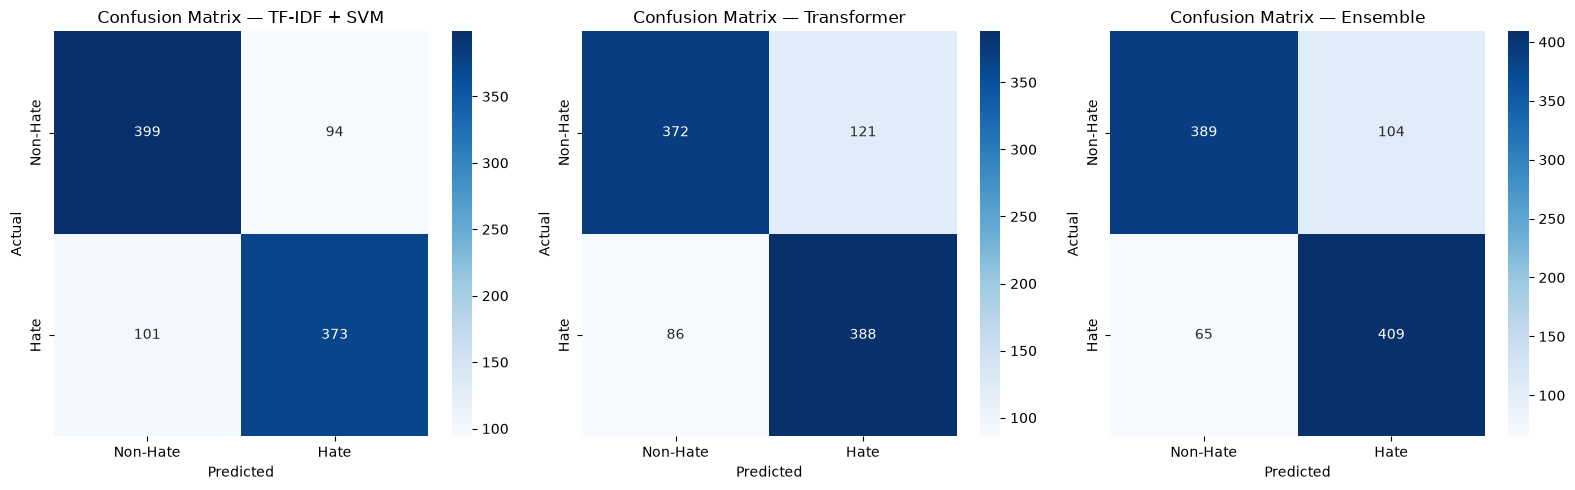

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (name, preds) in zip(
    axes,
    [("TF-IDF + SVM", val_preds_lr), ("Transformer", val_preds_transformer), ("Ensemble", val_preds_ensemble)]
):
    cm = confusion_matrix(y_val, preds)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["Non-Hate", "Hate"], yticklabels=["Non-Hate", "Hate"], ax=ax)
    ax.set_title(f"Confusion Matrix — {name}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

## Step 7 — Error Analysis\n\nInspect the comments the transformer model gets wrong — this tells you what kinds of hate speech (sarcasm, implicit hate, code-switch-heavy text, etc.) the model struggles with.

In [27]:
val_analysis = val_split.copy().reset_index(drop=True)
val_analysis["true_label"] = y_val
val_analysis["pred_label"] = val_preds_ensemble  # error analysis on the (usually strongest) ensemble
val_analysis["correct"] = val_analysis["true_label"] == val_analysis["pred_label"]

errors = val_analysis[~val_analysis["correct"]]
print(f"Total validation examples: {len(val_analysis)}")
print(f"Misclassified: {len(errors)} ({len(errors)/len(val_analysis)*100:.1f}%)")

false_positives = errors[(errors["true_label"] == 0) & (errors["pred_label"] == 1)]
false_negatives = errors[(errors["true_label"] == 1) & (errors["pred_label"] == 0)]

print(f"\nFalse Positives (predicted Hate, actually Non-Hate): {len(false_positives)}")
print(f"False Negatives (predicted Non-Hate, actually Hate): {len(false_negatives)}")

print("\n--- Sample False Positives ---")
display(false_positives[[TEXT_COL, "clean_text", "true_label", "pred_label"]].head(30))

print("\n--- Sample False Negatives ---")
display(false_negatives[[TEXT_COL, "clean_text", "true_label", "pred_label"]].head(30))

Total validation examples: 967
Misclassified: 169 (17.5%)

False Positives (predicted Hate, actually Non-Hate): 104
False Negatives (predicted Non-Hate, actually Hate): 65

--- Sample False Positives ---


,Comment,clean_text,true_label,pred_label
11,Le Sade gothildhe yaako vedio maadthiya......,le sade gothildhe yaako vedio maadthiya.,0,1
18,sarakara ulidre olle uta illa badoota,sarakara ulidre olle uta illa badoota,0,1
30,Big bulletin alli comedian rangannan jote huch...,big bulletin alli comedian rangannan jote huch...,0,1
43,Mad music olage iro muslim ninu... Dairyavagi ...,mad music olage iro muslim ninu. dairyavagi ni...,0,1
47,Nindee ondee sadani avldee Ind sadani thuu ka...,nindee ondee sadani avldee ind sadani thuu kac...,0,1
49,ella heli mugsi admele eega banda bhoopa,ella heli mugsi admele eega banda bhoopa,0,1
67,Many saba adyakshrige idella bekagillað¤ªð¤ª...,many saba adyakshrige idella bekagilla,0,1
71,Correct aghi mathadidare kaveri parvagi strike...,correct aghi mathadidare kaveri parvagi strike...,0,1
78,Ellellinda bandu illen torsodu avnu tegdakbek ...,ellellinda bandu illen torsodu avnu tegdakbek ...,0,1
86,Emergency exit muchappa ð,emergency exit muchappa,0,1



--- Sample False Negatives ---


,Comment,clean_text,true_label,pred_label
1,Intavrge RCB management women&#39;s mentor agi...,intavrge rcb management women 39 s mentor agi ...,1,0
5,@Deekshith Kundar prataf ð ð kav kav ð¥...,kundar prataf kav kav,1,0
22,Anamadheya enu...nimge kivi kelsalva idu indra...,anamadheya enu.nimge kivi kelsalva idu indraji...,1,0
40,Batroom yelrigintha..ninge changi gouthu...i ...,batroom yelrigintha.ninge changi gouthu.i phon...,1,0
63,Friends nanna 25 year na jivanada muslim forc...,friends nanna 25 year na jivanada muslim force...,1,0
70,Yavano comment madavne nodro kelage kohli bagg...,yavano comment madavne nodro kelage kohli bagg...,1,0
80,Sidda pedda,sidda pedda,1,0
82,Babu avre nimma banda vada thumba jasti aaythu...,babu avre nimma banda vada thumba jasti aaythu...,1,0
100,Nimmamnna badavaru accident ahgi sattru yaru y...,nimmamnna badavaru accident ahgi sattru yaru y...,1,0
108,Yaru support madlila siraj bai Ella support ma...,yaru support madlila siraj bai ella support ma...,1,0


## Step 8 — Select Final Best Model

Picks whichever of the three candidates (TF-IDF+SVM, Transformer, or the Ensemble of the two) scored
highest macro-F1 on the validation split (the standard metric for this shared task). In practice the
ensemble wins most of the time; ties go to the ensemble since it's the most robust choice. Edit the
logic below if you want to force a specific model.

In [29]:
f1_lr = results.loc[results["model"].str.contains("LinearSVC"), "f1_macro"].values[0]
f1_tf = results.loc[results["model"] == f"Transformer ({MODEL_NAME})", "f1_macro"].values[0]
f1_xlmr = results.loc[results["model"] == f"Transformer ({MODEL_NAME_2})", "f1_macro"].values[0]
f1_ens = results.loc[results["model"].str.startswith("Ensemble"), "f1_macro"].values[0]

scores = {"tfidf_svm": f1_lr, "transformer_muril": f1_tf, "transformer_xlmr": f1_xlmr, "ensemble": f1_ens}
BEST_MODEL = max(scores, key=scores.get)

print("Validation macro-F1 by candidate:")
for name, score in scores.items():
    marker = "  <-- selected" if name == BEST_MODEL else ""
    print(f"  {name:18s}: {score:.4f}{marker}")

# Always save all three underlying models, since the ensemble needs all of them at inference time.
trainer.save_model(os.path.join(OUTPUT_DIR, "best_model_muril"))
tokenizer.save_pretrained(os.path.join(OUTPUT_DIR, "best_model_muril"))

trainer2.save_model(os.path.join(OUTPUT_DIR, "best_model_xlmr"))
tokenizer2.save_pretrained(os.path.join(OUTPUT_DIR, "best_model_xlmr"))

import joblib
joblib.dump(svm_clf, os.path.join(OUTPUT_DIR, "best_model_svm.joblib"))
joblib.dump(tfidf, os.path.join(OUTPUT_DIR, "best_model_tfidf.joblib"))

w3 = 1 - best_w1 - best_w2

with open(os.path.join(OUTPUT_DIR, "best_model_meta.json"), "w") as f:
    json.dump({
        "BEST_MODEL": BEST_MODEL,
        "ensemble_weight_svm": float(best_w1),
        "ensemble_weight_muril": float(best_w2),
        "ensemble_weight_xlmr": float(w3),
        "ensemble_threshold": float(best_t),
        "scores": scores,
    }, f, indent=2)

print(f"\nFinal selection: {BEST_MODEL}")

Validation macro-F1 by candidate:
  tfidf_svm         : 0.7982
  transformer_muril : 0.7859
  transformer_xlmr  : 0.7714
  ensemble          : 0.8252  <-- selected


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Final selection: ensemble


## Step 9 — Competition Submission\n\nRuns the best model on the official test file (or the held-out internal test split, if no official test file was provided) and writes `submission.csv`.

In [31]:
if HAS_OFFICIAL_TEST:
    test_df = pd.read_csv(TEST_PATH)
else:
    test_df = test_split.copy()

# apply the SAME cleaning used for training
test_df["clean_text"] = test_df[TEXT_COL].apply(clean_text)

if ID_COL is not None and ID_COL in test_df.columns:
    submission_ids = test_df[ID_COL].values
else:
    submission_ids = np.arange(len(test_df))

def transformer_proba(texts, batch_size=32):
    encodings = tokenizer(
        list(texts), truncation=True, padding=True, max_length=MAX_LEN, return_tensors="pt"
    )
    model.eval()
    all_proba = []
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            batch = {k: v[i:i + batch_size].to(DEVICE) for k, v in encodings.items()}
            logits = model(**batch).logits
            proba = torch.softmax(logits, dim=-1)[:, 1].cpu().numpy()
            all_proba.extend(proba.tolist())
    return np.array(all_proba)

def transformer2_proba(texts, batch_size=32):
    encodings = tokenizer2(list(texts), truncation=True, padding=True, max_length=MAX_LEN, return_tensors="pt")
    model2.eval()
    all_proba = []
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            batch = {k: v[i:i + batch_size].to(DEVICE) for k, v in encodings.items()}
            logits = model2(**batch).logits
            proba = torch.softmax(logits, dim=-1)[:, 1].cpu().numpy()
            all_proba.extend(proba.tolist())
    return np.array(all_proba)

w3 = 1 - best_w1 - best_w2

if BEST_MODEL == "tfidf_svm":
    X_test_tfidf = tfidf.transform(test_df["clean_text"])
    final_preds = svm_clf.predict(X_test_tfidf)
elif BEST_MODEL == "transformer_muril":
    test_proba_tf = transformer_proba(test_df["clean_text"].tolist())
    final_preds = (test_proba_tf >= best_t).astype(int)
elif BEST_MODEL == "transformer_xlmr":
    test_proba_xlmr = transformer2_proba(test_df["clean_text"].tolist())
    final_preds = (test_proba_xlmr >= best_t).astype(int)
else:  # ensemble
    X_test_tfidf = tfidf.transform(test_df["clean_text"])
    test_proba_svm = svm_clf.predict_proba(X_test_tfidf)[:, 1]
    test_proba_muril = transformer_proba(test_df["clean_text"].tolist())
    test_proba_xlmr = transformer2_proba(test_df["clean_text"].tolist())
    test_proba_blend = best_w1 * test_proba_svm + best_w2 * test_proba_muril + w3 * test_proba_xlmr
    final_preds = (test_proba_blend >= best_t).astype(int)

submission = pd.DataFrame({
    "id": submission_ids,
    "label": final_preds
})
submission["label"] = submission["label"].map({0: "Non-Hate", 1: "Hate"})  # matches official format: id,label with Hate/Non-Hate

# Official HASTIKA submission rules: file must be named exactly "predictions.csv",
# header "id,label", zipped ALONE (no enclosing folder), UTF-8 encoding.
predictions_path = os.path.join(OUTPUT_DIR, "predictions.csv")
submission.to_csv(predictions_path, index=False, encoding="utf-8")
print(f"Saved predictions to: {predictions_path} (model used: {BEST_MODEL})")
submission.head(30)

Saved predictions to: /kaggle/working/predictions.csv (model used: ensemble)


,id,label
0,4186,Non-Hate
1,5693,Non-Hate
2,6825,Non-Hate
3,1468,Hate
4,6361,Hate
5,7793,Hate
6,5910,Hate
7,2380,Non-Hate
8,7438,Non-Hate
9,6653,Hate


In [32]:
import os
import zipfile

zip_path = os.path.join(OUTPUT_DIR, "predictions2.zip")

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    zf.write(predictions_path, arcname="predictions.csv")  # no folder nesting inside the zip

# Verify it actually exists on disk before trusting the Output tab
assert os.path.exists(zip_path), f"Zip was not created at {zip_path}"
print(f"Zipped submission ready at: {zip_path}  ({os.path.getsize(zip_path)} bytes)")

print("\nContents of /kaggle/working/:")
for f in sorted(os.listdir("/kaggle/working/")):
    print(" -", f)

print("\nDownload this .zip from the Kaggle 'Output' tab and upload it to CodaBench:")
print("https://www.codabench.org/competitions/17784/")


Zipped submission ready at: /kaggle/working/predictions2.zip  (2561 bytes)

Contents of /kaggle/working/:
 - .virtual_documents
 - best_model
 - best_model_meta.json
 - best_model_muril
 - best_model_svm.joblib
 - best_model_tfidf.joblib
 - best_model_xlmr
 - emoji_inspection.csv
 - emoticon_inspection.csv
 - predictions.csv
 - predictions2.zip
 - transformer_ckpt
 - transformer_ckpt_xlmr

Download this .zip from the Kaggle 'Output' tab and upload it to CodaBench:
https://www.codabench.org/competitions/17784/


In [ ]:
## Notes / things to double-check before you submit

1. **Submission is on CodaBench, not Kaggle**: https://www.codabench.org/competitions/17784/ — download `predictions.zip` from Kaggle's **Output** tab (right sidebar after the notebook finishes) and upload it there.
2. **The real, gold-labeled test set isn't out yet.** Per the HASTIKA repo, test inputs release 20 Sep and the deadline is 01 Oct. Until then, `binary_validation_inputs.csv` (806 unlabeled rows) is what you predict on — your CodaBench leaderboard score right now reflects that validation phase, not the final test.
3. **If your uploaded Kaggle dataset folder has a different name**, update the folder segment in `TRAIN_PATH`/`TEST_PATH` in the CONFIG cell (e.g. `/kaggle/input/<your-folder-name>/binary_train.csv`).
4. **If you get an out-of-memory error** on the transformer cell, lower `per_device_train_batch_size` to 8 in `TrainingArguments`.
5. **To try both MuRIL and XLM-R**, just change `MODEL_NAME` in the CONFIG cell and `Restart & Run All` again — then compare the `results` table (TF-IDF+SVM, Transformer, Ensemble).
6. **The scoring metric is macro-F1**, which weighs the Hate and Non-Hate classes equally — always compare models on the `f1_macro` column, not accuracy.
7. **If macro-F1 still looks off after re-running**, the most common causes are: the CONFIG cell pointing at a stale/wrong CSV, running cells out of order after editing one mid-notebook, or a Kaggle session that silently fell back to CPU (check the "Using device" print in Step 0).
8. This notebook only implements **Task A**. Task B (fine-grained target category classification into Gender/Political/Religion/Geo-political/Violence/Others, using `data/multiclass_train.csv`) is a separate multi-class notebook — ask if you want that built next.